**American Time Use Survey (ATUS) | 2003-2025**\
Data Visualization Semester Project\
Maxell Taylor\
Georgetown University

Data Source: U.S. Breau of Labor Statistics
https://www.bls.gov/tus/data.htm#

Exploratory analysis of American time-use data

In [22]:
# Load packages

library(tidyverse)
library(ggplot2)
library(ggthemes)
library(plotly)
library(dplyr)

Warning message:
"package 'ggthemes' was built under R version 4.6.2"


#========================================
# American Time Use Survey (ATUS) | 2003-2025
# Data Visualization Semester Project
# Maxell Taylor mct115
# Georgetown University
#
# Data Source: U.S. Breau of Labor Statistics
# https://www.bls.gov/tus/data.htm#
#
# Exploratory analysis of American time-use data
#========================================


In [12]:

# Import data

# Total minutes per activity per respondent for one day by demographic
atus_sum <- read_csv( 
  "data/raw/atussum_0325.dat",
  col_types = cols(
    TUCASEID = col_character(),
    .default = col_guess()
  )
)

# Additional respondent info such as employment, earnings, education
atus_resp <- read_csv(
  "data/raw/atusresp_0325.dat",
  col_types = cols(
    TUCASEID = col_character(),
    .default = col_guess()
  )
)

# Individual activities with stop time + duration
atus_act <- read_csv(
  "data/raw/atusact_0325.dat",
  col_types = cols(
    TUCASEID = col_character(),
    .default = col_guess()
  )
)


In [13]:
# Initial exploration 

# Dimensions
dim(atus_sum)  # 258954 x 456
dim(atus_resp) # 258954 x 133

# Column names --> join by TUCASEID
names(atus_sum)
names(atus_resp)

# Preview
head(atus_sum)
head(atus_resp)

[1] 258954    456

[1] 258954    133

[1] "TUCASEID"   "GEMETSTA"   "GTMETSTA"   "PEEDUCA"    "PEHSPNON"  
  [6] "PTDTRACE"   "TEAGE"      "TELFS"      "TEMJOT"     "TESCHENR"  
 [11] "TESCHLVL"   "TESEX"      "TESPEMPNOT" "TRCHILDNUM" "TRDPFTPT"  
 [16] "TRERNWA"    "TRHOLIDAY"  "TRSPFTPT"   "TRSPPRES"   "TRYHHCHILD"
 [21] "TUDIARYDAY" "TUFNWGTP"   "TEHRUSLT"   "TUYEAR"     "TU20FWGT"  
 [26] "t010101"    "t010102"    "t010199"    "t010201"    "t010299"   
 [31] "t010301"    "t010399"    "t010401"    "t010499"    "t010501"   
 [36] "t010599"    "t019999"    "t020101"    "t020102"    "t020103"   
 [41] "t020104"    "t020199"    "t020201"    "t020202"    "t020203"   
 [46] "t020299"    "t020301"    "t020302"    "t020303"    "t020399"   
 [51] "t020401"    "t020402"    "t020499"    "t020501"    "t020502"   
 [56] "t020599"    "t020681"    "t020699"    "t020701"    "t020799"   
 [61] "t020801"    "t020899"    "t020901"    "t020902"    "t020903"   
 [66] "t020904"    "t020905"    "t020999"    "t029999"    "t030101"   
 [71] "t030102"    "t030103"    "t030104"    "t030105"    "t030108"   
 [76] "t030109"    "t030110"    "t030111"    "t030112"    "t030186"   
 [81] "t030199"    "t030201"    "t030202"    "t030203"    "t030204"   
 [86] "t030299"    "t030301"    "t030302"    "t030303"    "t030399"   
 [91] "t030401"    "t030402"    "t030403"    "t030404"    "t030405"   
 [96] "t030499"    "t030501"    "t030502"    "t030503"    "t030504"   
[101] "t030599"    "t039999"    "t040101"    "t040102"    "t040103"   
[106] "t040104"    "t040105"    "t040108"    "t040109"    "t040110"   
[111] "t040111"    "t040112"    "t040186"    "t040199"    "t040201"   
[116] "t040202"    "t040203"    "t040204"    "t040299"    "t040301"   
[121] "t040302"    "t040303"    "t040399"    "t040401"    "t040402"   
[126] "t040403"    "t040404"    "t040405"    "t040499"    "t040501"   
[131] "t040502"    "t040503"    "t040504"    "t040505"    "t040506"   
[136] "t040507"    "t040508"    "t040599"    "t049999"    "t050101"   
[141] "t050102"    "t050103"    "t050189"    "t050201"    "t050202"   
[146] "t050203"    "t050204"    "t050289"    "t050301"    "t050302"   
[151] "t050303"    "t050304"    "t050389"    "t050403"    "t050404"   
[156] "t050405"    "t050481"    "t050499"    "t059999"    "t060101"   
[161] "t060102"    "t060103"    "t060104"    "t060199"    "t060201"   
[166] "t060202"    "t060203"    "t060289"    "t060301"    "t060302"   
[171] "t060303"    "t060399"    "t060401"    "t060402"    "t060403"   
[176] "t060499"    "t069999"    "t070101"    "t070102"    "t070103"   
[181] "t070104"    "t070105"    "t070199"    "t070201"    "t070299"   
[186] "t070301"    "t070399"    "t079999"    "t080101"    "t080102"   
[191] "t080199"    "t080201"    "t080202"    "t080203"    "t080299"   
[196] "t080301"    "t080302"    "t080399"    "t080401"    "t080402"   
[201] "t080403"    "t080499"    "t080501"    "t080502"    "t080599"   
[206] "t080601"    "t080602"    "t080699"    "t080701"    "t080702"   
[211] "t080799"    "t080801"    "t080899"    "t089999"    "t090101"   
[216] "t090102"    "t090103"    "t090104"    "t090199"    "t090201"   
[221] "t090202"    "t090299"    "t090301"    "t090302"    "t090399"   
[226] "t090401"    "t090402"    "t090499"    "t090501"    "t090502"   
[231] "t090599"    "t099999"    "t100101"    "t100102"    "t100103"   
[236] "t100199"    "t100201"    "t100299"    "t100381"    "t100383"   
[241] "t100399"    "t100401"    "t100499"    "t109999"    "t110101"   
[246] "t110199"    "t110281"    "t110289"    "t119999"    "t120101"   
[251] "t120199"    "t120201"    "t120202"    "t120299"    "t120301"   
[256] "t120302"    "t120303"    "t120304"    "t120305"    "t120306"   
[261] "t120307"    "t120308"    "t120309"    "t120310"    "t120311"   
[266] "t120312"    "t120313"    "t120399"    "t120401"    "t120402"   
[271] "t120403"    "t120404"    "t120405"    "t120499"    "t120501"   
[276] "t120502"    "t120503"    "t120504"    "t120599"    "t129999"   
[281] "t130101"    "t13010

[1] "TUCASEID"     "TULINENO"     "TESPUHRS"     "TRDTIND1"     "TRDTOCC1"    
  [6] "TRERNHLY"     "TRERNUPD"     "TRHERNAL"     "TRHHCHILD"    "TRIMIND1"    
 [11] "TRMJIND1"     "TRMJOCC1"     "TRMJOCGR"     "TRNHHCHILD"   "TRNUMHOU"    
 [16] "TROHHCHILD"   "TRTALONE"     "TRTCC"        "TRTHHFAMILY"  "TRTNOCHILD"  
 [21] "TRTNOHH"      "TRTO"         "TRTOHH"       "TRTOHHCHILD"  "TRTONHH"     
 [26] "TRTONHHCHILD" "TRTSPONLY"    "TRTSPOUSE"    "TRTUNMPART"   "TRWERNAL"    
 [31] "TTHR"         "TTOT"         "TTWK"         "TUABSOT"      "TUYEAR"      
 [36] "TEABSRSN"     "TEERN"        "TEERNH1O"     "TEERNH2"      "TEERNHRO"    
 [41] "TEERNHRY"     "TEERNPER"     "TEERNRT"      "TEERNUOT"     "TEERNWKP"    
 [46] "TEHRFTPT"     "TEHRUSL1"     "TEHRUSL2"     "TEIO1COW"     "TEIO1ICD"    
 [51] "TEIO1OCD"     "TELAYAVL"     "TELAYLK"      "TELKAVL"      "TELKM1"      
 [56] "TERET1"       "TESCHFT"      "TUBUS"        "TUBUS1"       "TUBUS2OT"    
 [61] "TUBUSL1"      "TUBUSL2"      "TUBUSL3"      "TUBUSL4"      "TUCC2"       
 [66] "TUCC4"        "TUFWK"        "TUIO1MFG"     "TUIODP1"      "TUIODP2"     
 [71] "TUIODP3"      "TULAY"        "TULAY6M"      "TULAYAVR"     "TULAYDT"     
 [76] "TULK"         "TULKAVR"      "TULKDK1"      "TULKDK2"      "TULKDK3"     
 [81] "TULKDK4"      "TULKM2"       "TULKM3"       "TULKM4"       "TULKM5"      
 [86] "TULKM6"       "TULKPS1"      "TULKPS2"      "TULKPS3"      "TULKPS4"     
 [91] "TUMONTH"      "TRTCCC"       "TRTCCTOT"     "TRTCHILD"     "TRTCOC"      
 [96] "TRTFAMILY"    "TRTFRIEND"    "TRTHH"        "TUDIS2"       "TURETOT"     
[101] "TUSPABS"      "TUSPUSFT"     "TUSPWK"       "TREMODR"      "TUCC9"       
[106] "TUDIARYDATE"  "TUDIS"        "TUDIS1"       "TRCHILDNUM"   "TUDIARYDAY"  
[111] "TRERNWA"      "TRHOLIDAY"    "TRSPFTPT"     "TRSPPRES"     "TRDPFTPT"    
[116] "TUFNWGTP"     "TESPEMPNOT"   "TESCHLVL"     "TESCHENR"     "TEMJOT"      
[121] "TELFS"        "TEHRUSLT"     "TRYHHCHILD"   "TRWBMODR"     "TRTALONE_WK" 
[126] "TRTCCC_WK"    "TRLVMODR"     "TRTEC"        "TUECYTD"      "TUELDER"     
[131] "TUELFREQ"     "TUELNUM"      "TU20FWGT"

TUCASEID,GEMETSTA,GTMETSTA,PEEDUCA,PEHSPNON,PTDTRACE,TEAGE,TELFS,TEMJOT,TESCHENR,⋯,t181801,t181899,t189999,t500101,t500103,t500104,t500105,t500106,t500107,t509989
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
20030100013280,1,-1,44,2,2,60,2,2,-1,⋯,0,0,0,0,0,0,0,0,0,0
20030100013344,2,-1,40,2,1,41,1,2,2,⋯,0,0,0,0,0,0,0,0,0,0
20030100013352,1,-1,41,2,1,26,2,2,2,⋯,0,0,0,0,0,0,0,0,0,0
20030100013848,2,-1,39,2,2,36,4,-1,2,⋯,0,0,0,0,0,0,0,0,0,0
20030100014165,2,-1,45,2,1,51,1,2,-1,⋯,0,0,0,0,0,0,0,0,0,0
20030100014169,2,-1,43,2,1,32,2,2,1,⋯,0,0,0,0,0,0,0,0,0,0


TUCASEID,TULINENO,TESPUHRS,TRDTIND1,TRDTOCC1,TRERNHLY,TRERNUPD,TRHERNAL,TRHHCHILD,TRIMIND1,⋯,TRWBMODR,TRTALONE_WK,TRTCCC_WK,TRLVMODR,TRTEC,TUECYTD,TUELDER,TUELFREQ,TUELNUM,TU20FWGT
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
20030100013280,1,-1,40,8,2200,1,1,2,15,⋯,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1
20030100013344,1,50,16,16,-1,1,-1,1,5,⋯,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1
20030100013352,1,-1,43,15,1250,0,0,2,16,⋯,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1
20030100013848,1,40,-1,-1,-1,-1,-1,1,-1,⋯,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1
20030100014165,1,-1,42,10,-1,-1,-1,1,16,⋯,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1
20030100014169,1,40,40,8,-1,1,-1,1,15,⋯,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1


In [14]:
# Check duplicate respondent IDs --> none

atus_sum |> count(TUCASEID) |> filter(n > 1)
atus_resp |> count(TUCASEID) |> filter(n > 1)

# df is way to big to parse visually, split as follows

# Identify activity columns

# used ChatGPT for pattern syntax: ^ = beginning of string,
# {6} = repetitions of pattern, $ = end of string
activity_columns <- names(atus_sum)[
  grepl("^t[0-9]{6}$", names(atus_sum))
]

length(activity_columns)
head(activity_columns)

respondent_columns <- setdiff(
  names(atus_sum),
  activity_columns
)
respondent_columns

TUCASEID,n
<chr>,<int>


TUCASEID,n
<chr>,<int>


[1] 431

[1] "t010101" "t010102" "t010199" "t010201" "t010299" "t010301"

[1] "TUCASEID"   "GEMETSTA"   "GTMETSTA"   "PEEDUCA"    "PEHSPNON"  
 [6] "PTDTRACE"   "TEAGE"      "TELFS"      "TEMJOT"     "TESCHENR"  
[11] "TESCHLVL"   "TESEX"      "TESPEMPNOT" "TRCHILDNUM" "TRDPFTPT"  
[16] "TRERNWA"    "TRHOLIDAY"  "TRSPFTPT"   "TRSPPRES"   "TRYHHCHILD"
[21] "TUDIARYDAY" "TUFNWGTP"   "TEHRUSLT"   "TUYEAR"     "TU20FWGT"

TUYEAR,n
<dbl>,<int>
2003,20720
2004,13973
2005,13038
2006,12943
2007,12248
2008,12723
2009,13133
2010,13260
2011,12479


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  15.00   34.00   47.00   48.45   63.00   85.00 

TESEX,n
<dbl>,<int>
1,114974
2,143980


TUDIARYDAY,n
<dbl>,<int>
1,66457
2,26362
3,26112
4,26042
5,25564
6,25266
7,63151


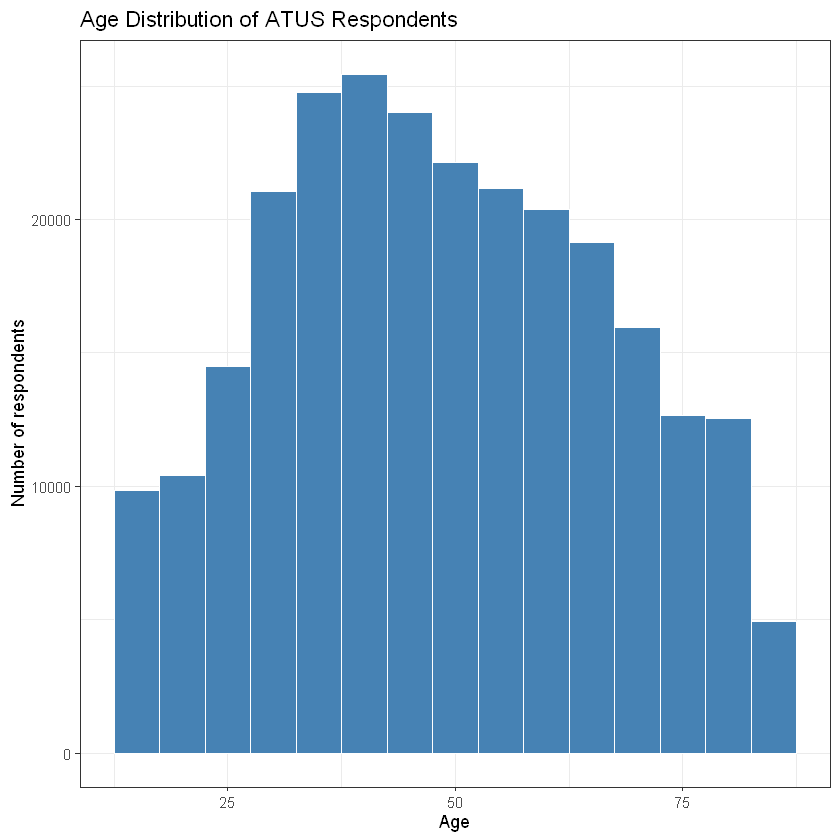

In [ ]:
# Respondent characteristics exploration

# respondents per year
atus_sum |> count(TUYEAR)

# Age distribution
summary(atus_sum$TEAGE)

p_age <- ggplot(atus_sum, aes(x = TEAGE)) +
  geom_histogram(binwidth = 5, fill = "steelblue", color = "white") +
  labs(
    title = "Age Distribution of ATUS Respondents",
    x = "Age",
    y = "Number of respondents"
  ) +
  theme_bw()

p_age

# Sex distribution
atus_sum |> count(TESEX)
  # 1 = male, 2 = female
  # 114974 male (44.4%) vs 143980 female (55.6%)


